# VM0047 on a real plot: what has happened so far, and what to expect over ten years

This notebook applies Verra's VM0047 rules to a 1.27 ha plot in Chikkamagaluru, treated as a **new arecanut planting** made in June 2025. It shows the plot, the record so far, and the credits expected over ten years.

**Read this first.**

- The plot is real. The planting is a what-if: the real plot is an established garden, which VM0047 would not credit as a new project.
- Tree sizes are measured values from a Malnad field trial (Bhoomika et al. 2023), not measurements of this plot. The years in between are modelled.
- No credits are issued here. Only a registry issues credits, after an accredited verifier has checked field measurements.

Sections 1 to 11 need no login. Section 12 is optional and needs Earth Engine.

In [1]:
# Setup: get the repository if this notebook is running on its own (for example in Colab).
import os, sys
REPO_URL = "https://github.com/satvikkalyanpur/mrv-vm0047-exante.git"   # change if your repository has another name
if not os.path.exists("mrv"):
    if os.path.exists("../mrv"):
        os.chdir("..")
    else:
        !git clone -q {REPO_URL} repo
        os.chdir("repo")
sys.path.insert(0, os.getcwd())

import json
from datetime import date
import pandas as pd
import matplotlib.pyplot as plt
from mrv import pipeline, figures, benchmark, ledger, observe
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 110)
plt.rcParams["figure.dpi"] = 110
result = pipeline.run()
sc, rules, s = result.scenario, result.rules, result.summary
print("Engine loaded.")

Engine loaded.


## 1. The plot

The same parcel as our proof of concept: four corners, 1.27 ha, near 13.400° N, 75.759° E.

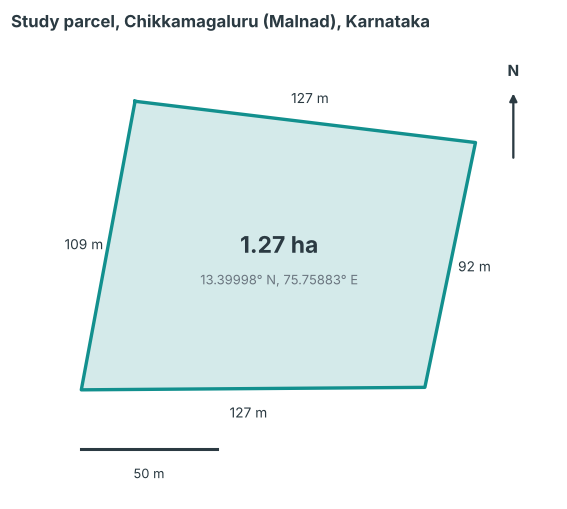

In [2]:
figures.parcel_map(sc["site"]["parcel_geojson"], sc["site"]["area_ha"]); plt.show()

The boundary on satellite imagery (loads in Colab or Jupyter; it does not show in GitHub's preview):

In [3]:
try:
    import folium
    ring = json.load(open(sc["site"]["parcel_geojson"]))["features"][0]["geometry"]["coordinates"][0]
    lat, lon = observe.parcel_centroid(sc["site"]["parcel_geojson"])
    m = folium.Map(location=[lat, lon], zoom_start=17, tiles=None)
    folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                     attr="Esri World Imagery", name="Satellite").add_to(m)
    folium.Polygon([(p[1], p[0]) for p in ring], color="#D9722A", weight=3, fill=False).add_to(m)
    display(m)
except ImportError:
    print("folium is not installed; run `pip install folium` to see the satellite map.")

## 2. What has been observed at the plot

One satellite measurement of this plot exists already: the proof of concept measured a mean NDVI of 0.873 from Sentinel-2 for November 2024 to March 2025, which is dense, established canopy.

The cell below can add rainfall (NASA POWER) and greenness (MODIS, 250 m) from November 2024 to today. Both are free and need no login. Set `COLLECT = True` to fetch them; the files are saved in `data/observed/` so the record stays with the repository.

Observed files present: ndvi_poc


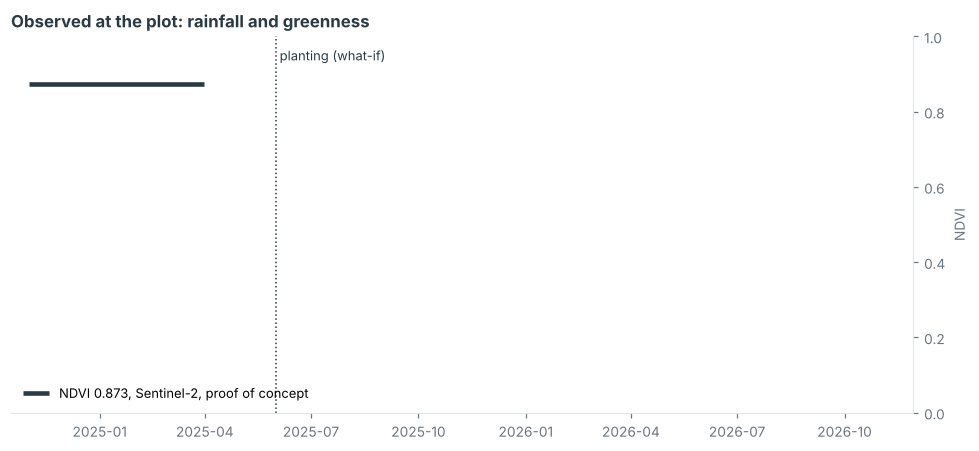

,period_start,period_end,sensor,resolution_m,statistic,ndvi,source
0,2024-11-01,2025-03-31,Sentinel-2 SR (COPERNICUS/S2_SR_HARMONIZED),10,parcel mean of cloud-filtered median composite,0.873,mrv-reference-pipeline v1.0.0 (doi:10.5281/zenodo.22026520)


In [4]:
COLLECT = False
if COLLECT:
    report = observe.collect(sc["site"]["parcel_geojson"], "data/observed",
                             date(2024, 11, 1), date.fromisoformat(sc["timeline"]["as_of"]))
    for k, v in report.items(): print(f"{k:26s} {v}")
obs = observe.load("data/observed")
print("Observed files present:", ", ".join(obs) or "none")
figures.observed_record(obs, sc["timeline"]["project_start"], sc["timeline"]["as_of"]); plt.tight_layout(); plt.show()
obs["ndvi_poc"]

## 3. The rules

Every number in this table is a rule of VM0047 or of the two Verra tools it points to. None is our choice.

In [5]:
r = rules
pd.DataFrame([
    ["Carbon fraction of dry biomass", r["constants"]["carbon_fraction"], "VM0047 parameter CF (IPCC 2006)"],
    ["Carbon to CO2", "44/12", "VM0047 Eq. (1)"],
    ["Census-based approach limit", f'{r["approach_selection"]["census_max_planting_units_per_ha"]} planting units/ha', "VM0047 v1.1 applicability"],
    ["Uncertainty, ex ante", f'at least {r["uncertainty"]["exante_minimum_deduction"]:.0%}', "VM0047 Section 8.6"],
    ["Uncertainty, ex post", f'only the part above {r["uncertainty"]["allowance"]:.0%} (90% CI)', "VM0047 Eqs. (27), (28)"],
    ["Performance benchmark", "credit only growth beyond matched control plots", "VM0047 Appendix 1, Eqs. (A5), (A6)"],
    ["Ex-ante horizon", f'{r["exante"]["horizon_years"]} years', "VM0047 Section 8.6"],
    ["Monitoring interval", f'at most {r["monitoring"]["max_interval_years"]} years', "VM0047 Section 9"],
    ["Leakage defaults", f'{r["leakage"]["supply_increase_share"]:.0%} supply response, {r["leakage"]["new_land_share"]:.0%} from new land', "VMD0054"],
    ["Buffer", f'at least {r["buffer"]["minimum_rating"]}%, fail above {r["buffer"]["fail_overall"]}', "AFOLU Non-Permanence Risk Tool v4.2"],
], columns=["Rule", "Value", "Source"])

,Rule,Value,Source
0,Carbon fraction of dry biomass,0.47,VM0047 parameter CF (IPCC 2006)
1,Carbon to CO2,44/12,VM0047 Eq. (1)
2,Census-based approach limit,50 planting units/ha,VM0047 v1.1 applicability
3,"Uncertainty, ex ante",at least 10%,VM0047 Section 8.6
4,"Uncertainty, ex post",only the part above 10% (90% CI),"VM0047 Eqs. (27), (28)"
5,Performance benchmark,credit only growth beyond matched control plots,"VM0047 Appendix 1, Eqs. (A5), (A6)"
6,Ex-ante horizon,10 years,VM0047 Section 8.6
7,Monitoring interval,at most 5 years,VM0047 Section 9
8,Leakage defaults,"75% supply response, 40% from new land",VMD0054
9,Buffer,"at least 12%, fail above 60",AFOLU Non-Permanence Risk Tool v4.2


## 4. The planting, and which VM0047 approach applies

Sparse planting that leaves the land use unchanged is *census-based*. Dense planting that closes canopy over more than a hectare is *area-based*, and must pass a performance benchmark against control plots.

In [6]:
est = sc["establishment"]
print("Scenario :", sc["name"])
print("Planted  :", sc["timeline"]["project_start"], "on", sc["land_at_start"]["state"])
print(f'Spacing  : {sc["stand"]["spacing_m"]} m x {sc["stand"]["spacing_m"]} m = {s["palms_per_ha"]:.0f} palms/ha, '
      f'{s["palms_per_ha"] * s["area_ha"]:.0f} palms on {s["area_ha"]} ha')
print(f'Seedlings: {est["seedling_age_at_planting_months"]} months old at planting; bearing starts after {est["pre_bearing_years"]} years (CPCRI)')
print("Approach :", result.approach.upper(), "-", result.approach_reason)

Scenario : Arecanut new planting, Chikkamagaluru parcel (what-if)
Planted  : 2025-06-01 on fallow non-forest land
Spacing  : 2.7 m x 2.7 m = 1372 palms/ha, 1742 palms on 1.27 ha
Seedlings: 12-18 months old at planting; bearing starts after 5-8 years (CPCRI)
Approach : AREA-BASED - 1372 planting units/ha exceeds the census limit of 50/ha, and the planting forms continuous cover over 1.27 ha.


Quantifying carbon does not make a project eligible. A real project would still have to show these:

In [7]:
pd.DataFrame([c.__dict__ for c in result.checks]).rename(columns={"rule": "Condition", "status": "Status", "note": "Note"})

,Condition,Status,Note
0,Project activity increases vegetative cover,pass,"Scenario assumes 0 % woody cover at the start. The real parcel is an established garden, so this holds onl..."
1,No clearing of woody vegetation in the 10 years before the start,pass,Assumed in the scenario; a real project shows it with a 10-year stocking-index record.
2,Leakage from displaced production (VMD0054),pass,"Fallow land: no production displaced, so leakage is zero."
3,Additionality step 1: regulatory surplus,not shown,Needs a check that no law or programme requires the planting.
4,Additionality step 2: performance benchmark,not shown,"Needs at least 30 project plots and matched control plots from satellite data, re-tested at every verifica..."
5,Additionality step 3: investment barrier,not shown,"Arecanut earns nut revenue, so an investment analysis is required. A profitable cash crop is hard to show ..."


## 5. Biomass at year 10

Height and diameter of 10-year-old palms are measured values for eight cultivars in Malnad. Biomass per palm comes from a species equation fitted to 40 palms that were cut down and weighed in India (Das et al. 2021, height model): 80% above ground, 20% below.

In [8]:
result.cultivars.round(2)

,cultivar,height_m,stem_diameter_cm,agb_kg_per_palm,bgb_kg_per_palm,carbon_t_per_ha,co2e_t_per_ha,within_equation_range
0,Thirthahalli local,7.25,17.10,12.85,3.21,10.36,37.98,True
1,Sagara local,7.64,16.88,13.99,3.50,11.27,41.33,True
2,Tarikere local,8.24,14.68,15.81,3.95,12.74,46.71,True
3,SAS-1,9.02,17.38,18.29,4.57,14.74,54.06,True
4,Mangala,7.06,11.78,12.31,3.08,9.92,36.38,True
5,Sumangala,7.21,15.92,12.74,3.18,10.27,37.64,True
6,Sreemangala,8.02,15.56,15.13,3.78,12.19,44.71,True
7,Mohit Nagar,7.95,16.47,14.92,3.73,12.02,44.08,True


In [9]:
print(f'Spread between cultivars (90% CI half-width): {s["uncertainty_estimated"]:.1%}')
print(f'Uncertainty deduction applied               : {s["uncertainty_deducted"]:.0%}  (VM0047 ex-ante floor is 10%)')

Spread between cultivars (90% CI half-width): 9.2%
Uncertainty deduction applied               : 10%  (VM0047 ex-ante floor is 10%)


## 6. So far: the first 17 months

Month by month from planting to today. Field stages are CPCRI's recommended practice. Stock and credits are modelled: palms this young are far below the height range of the biomass equation, so treat these as indicative. Nothing is issued before the first verification.

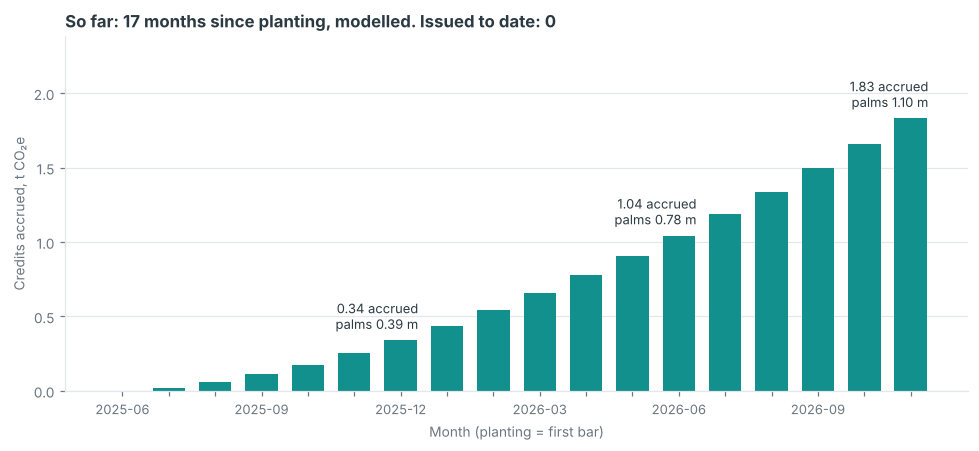

,month,date,mean_height_m,stock_change_tco2e,credits_accrued,credits_issued,field_stage
0,0,2025-06-01,0.00,0.00,0.00,0.0,Transplant 12-18-month nursery seedlings (5 or more leaves) into 90 cm pits; shade and irrigation start
6,6,2025-12-01,0.39,0.43,0.34,0.0,"First dry season: irrigate every 3-5 days, keep shade; count survivors"
12,12,2026-06-01,0.78,1.32,1.04,0.0,"Year-1 census: count survivors, cull palms under 20 cm girth"
17,17,2026-11-01,1.10,2.31,1.83,0.0,Second dry season begins; palms still pre-bearing (bearing starts at 5-8 years)


In [10]:
progress = pipeline.progress_to_date(result)
figures.progress_so_far(progress, s["as_of"]); plt.tight_layout(); plt.show()
show = progress[progress.month.isin([0, 6, 12, progress.month.max()])]
show[["month", "date", "mean_height_m", "stock_change_tco2e", "credits_accrued", "credits_issued", "field_stage"]].round(2)

## 7. Expected: ten years

Credits accrue every year but are issued only at verification, here in years 5 and 10.

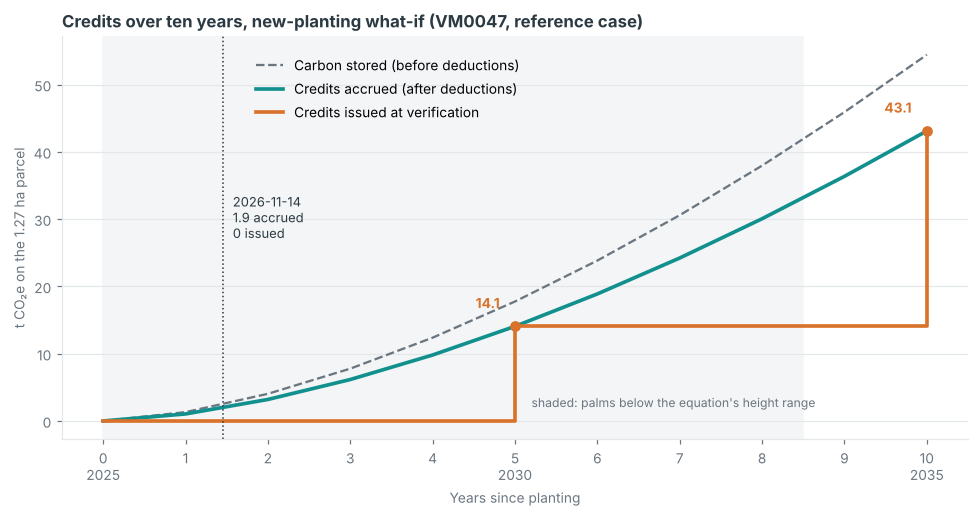

,year,calendar_year,mean_height_m,stock_change_tco2e,net_removals_cumulative_tco2e,buffer_in_year_tco2e,credits_accrued_cumulative,credits_issued_cumulative
0,0,2025,0.00,0.00,0.00,0.00,0.00,0.00
1,1,2026,0.78,1.32,1.19,0.14,1.04,0.00
2,2,2027,1.56,4.04,3.64,0.29,3.20,0.00
3,3,2028,2.34,7.78,7.00,0.40,6.16,0.00
4,4,2029,3.12,12.38,11.14,0.50,9.81,0.00
5,5,2030,3.90,17.76,15.98,0.58,14.06,14.06
6,6,2031,4.68,23.84,21.46,0.66,18.88,14.06
7,7,2032,5.46,30.59,27.53,0.73,24.23,14.06
8,8,2033,6.24,37.95,34.16,0.80,30.06,14.06
9,9,2034,7.02,45.91,41.32,0.86,36.36,14.06


In [11]:
figures.credits_over_time(result); plt.tight_layout(); plt.show()
cols = ["year", "calendar_year", "mean_height_m", "stock_change_tco2e", "net_removals_cumulative_tco2e",
        "buffer_in_year_tco2e", "credits_accrued_cumulative", "credits_issued_cumulative"]
result.schedule[cols].round(2)

## 8. From carbon stored to credits issuable

The reference case sets every deduction at the lowest value the methodology allows, so it is an upper bound.

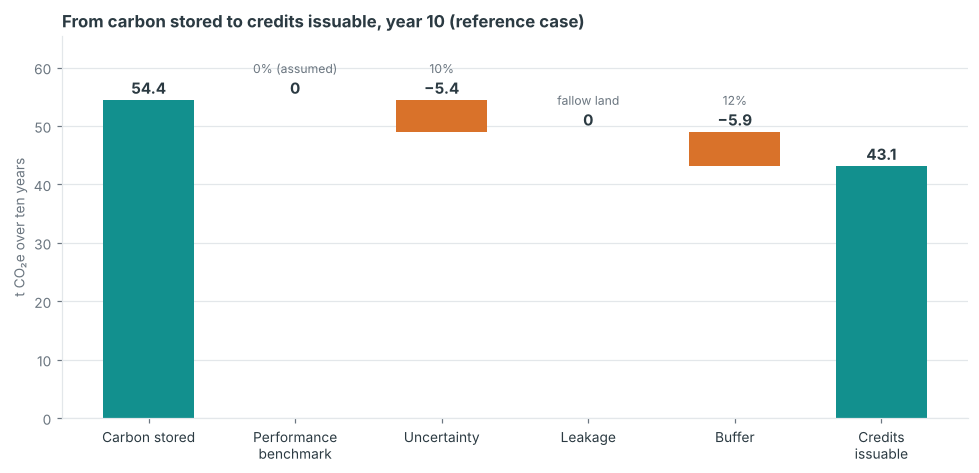

Carbon stored by year 10 : 54.4 t CO2e
Credits issuable         : 43.1  = 3.39 per hectare per year
With illustrative deductions (benchmark 13%, uncertainty 15%, buffer 20%): 32.2


In [12]:
figures.waterfall(result); plt.tight_layout(); plt.show()
print(f'Carbon stored by year 10 : {s["stock_change_tco2e"]:.1f} t CO2e')
print(f'Credits issuable         : {s["credits_issuable"]:.1f}  = {s["credits_per_ha_per_year"]:.2f} per hectare per year')
illustrative = pipeline.run(pipeline.with_overrides(sc, **sc["illustrative_case"]), rules)
print(f'With illustrative deductions (benchmark 13%, uncertainty 15%, buffer 20%): {illustrative.summary["credits_issuable"]:.1f}')

## 9. Reality check against measured stands

Is the year-10 figure believable? Das et al. measured whole stands of 10 to 35 years in Assam. Their palms hold 10.5 to 12.0 kg of carbon each. The model gives less than that per palm at year 10, so it errs on the low side.

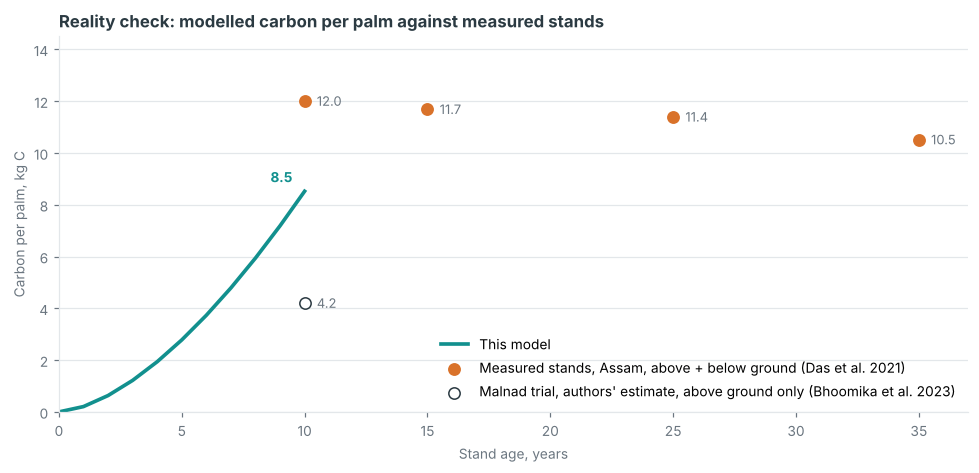

,source,location,age_years,palms_per_ha,carbon_t_per_ha,carbon_kg_per_palm,pools
0,This model,"Chikkamagaluru (Malnad), Karnataka, India",10,1372,11.69,8.52,above + below ground
1,Das et al. 2021,"Karimganj, Assam",10,650,7.80,12.00,above + below ground
2,Das et al. 2021,"Karimganj, Assam",15,1575,18.40,11.68,above + below ground
3,Das et al. 2021,"Karimganj, Assam",25,1800,20.50,11.39,above + below ground
4,Das et al. 2021,"Karimganj, Assam",35,1950,20.50,10.51,above + below ground
5,Bhoomika et al. 2023,"Thirthahalli, Karnataka",10,1372,5.76,4.20,above ground only


In [13]:
check = pipeline.reality_check(result)
figures.reality_check(result, check); plt.tight_layout(); plt.show()
check[["source", "location", "age_years", "palms_per_ha", "carbon_t_per_ha", "carbon_kg_per_palm", "pools"]].round(2)

## 10. What moves the answer, and where the trees go

One input is changed at a time. The biomass equation matters far more than any deduction.

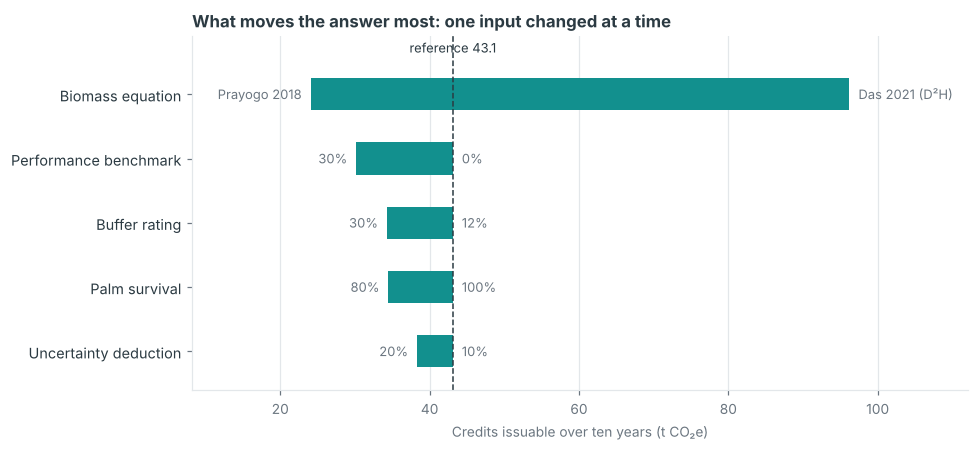

If the same palms replaced a working field instead of fallow (VMD0054):
  new land brought into production elsewhere: 0.38 ha
  leakage cancels all 49 t CO2e of removals if that land holds more than 35 t C per ha


In [14]:
sens = pipeline.sensitivity(sc, rules)
figures.sensitivity_ranges(sens, s["credits_issuable"]); plt.tight_layout(); plt.show()
crop = pipeline.cropland_alternative(result)
print("If the same palms replaced a working field instead of fallow (VMD0054):")
print(f'  new land brought into production elsewhere: {crop["new_land_ha"]:.2f} ha')
print(f'  leakage cancels all {crop["removals_before_leakage_tco2e"]:.0f} t CO2e of removals if that land holds more than '
      f'{crop["breakeven_carbon_stock_tc_per_ha"]:.0f} t C per ha')

Why the real, existing garden earns nothing: for dense planting, growth is compared with matched control plots and only the difference is credited. The slopes below are illustrative, not satellite data; they show how the rule behaves.

In [15]:
T = benchmark.Trend
cases = {
    "New planting on fallow, controls flat":      (T(0.150, 0.010, 0.0001, 10), T(0.002, 0.004, 0.60, 10)),
    "New planting, controls regrowing slowly":    (T(0.150, 0.010, 0.0001, 10), T(0.020, 0.005, 0.01, 10)),
    "Existing garden vs neighbouring gardens":    (T(0.010, 0.004, 0.03, 10),   T(0.009, 0.004, 0.04, 10)),
}
pd.DataFrame([{"Case": k, "Z": round(benchmark.z_statistic(p, c), 2),
               "Benchmark PB": round(benchmark.performance_benchmark(p, c), 2),
               "Share credited": f"{1 - benchmark.performance_benchmark(p, c):.0%}"} for k, (p, c) in cases.items()])

,Case,Z,Benchmark PB,Share credited
0,"New planting on fallow, controls flat",13.74,0.00,100%
1,"New planting, controls regrowing slowly",11.63,0.13,87%
2,Existing garden vs neighbouring gardens,0.18,1.00,0%


## 11. Integrity log

Each input file and each headline result is recorded in a SHA-256 hash chain. Changing any entry breaks every hash after it.

In [16]:
import copy
chain = pipeline.build_ledger(result, pipeline.INPUT_FILES)
for e in chain:
    print(f'{e.get("file", e.get("name")):45s} {str(e.get("value", "")):>10s}  {e["hash"][:16]}')
print("\nChain verifies:", ledger.verify_chain(chain))
tampered = copy.deepcopy(chain); tampered[-1]["value"] = 99.0
print("After editing the credit figure:", ledger.verify_chain(tampered))

config/vm0047_v1_1.yaml                                   32ea453e45817093
config/scenario_arecanut_newplanting.yaml                 66386304c5345843
data/growth_anchor_bhoomika2023.csv                       47f3d62d68af310c
data/parcel.geojson                                       73fc2fcb027b813d
data/reference_stands.csv                                 3e3025335b9f7361
stock_change_tco2e                               54.4333  72139a7baa670ca1
uncertainty_deducted                                 0.1  b7cc7c2092dd42d9
performance_benchmark                                0.0  c61a73a4a8e6bb20
buffer_fraction                                     0.12  4b378c3d1a6dcb0a
net_removals_tco2e                                 48.99  6277a696bb4b8965
credits_issuable                                 43.1112  070e1284af7dffee

Chain verifies: True
After editing the credit figure: False


## 12. Optional: the plot at 10 m from Sentinel-2 (needs Earth Engine)

Monthly NDVI of the parcel itself, from November 2024 to today, saved to `data/observed/ndvi_sentinel2_10m.csv`. Cloudy monsoon months come back empty. Set `RUN_EE = True` and enter your Earth Engine project ID.

In [17]:
RUN_EE = False
EE_PROJECT = "your-earth-engine-project-id"
if RUN_EE:
    !pip install -q earthengine-api
    import ee
    ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
    ring = json.load(open(sc["site"]["parcel_geojson"]))["features"][0]["geometry"]["coordinates"]
    aoi = ee.Geometry.Polygon(ring)
    s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi)
          .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 30)))
    rows, end = [], date.fromisoformat(sc["timeline"]["as_of"])
    y, mo = 2024, 11
    while (y, mo) <= (end.year, end.month):
        start = ee.Date.fromYMD(y, mo, 1)
        col = s2.filterDate(start, start.advance(1, "month"))
        n = col.size().getInfo()
        ndvi = None
        if n > 0:
            img = col.median().normalizedDifference(["B8", "B4"]).rename("NDVI")
            ndvi = img.reduceRegion(ee.Reducer.mean(), aoi, 10).get("NDVI").getInfo()
        rows.append({"date": f"{y}-{mo:02d}-15", "ndvi": ndvi, "images": n})
        y, mo = (y + 1, 1) if mo == 12 else (y, mo + 1)
    s2_series = pd.DataFrame(rows)
    s2_series.to_csv("data/observed/ndvi_sentinel2_10m.csv", index=False)
    figures.observed_record(observe.load("data/observed"), sc["timeline"]["project_start"], sc["timeline"]["as_of"]); plt.show()
    display(s2_series)
else:
    print("Skipped. Everything above runs without Earth Engine.")

Skipped. Everything above runs without Earth Engine.


## What is measured, cited and assumed

| Item | Status |
|---|---|
| Plot boundary and area | Real: the proof-of-concept parcel |
| NDVI 0.873, Nov 2024 to Mar 2025 | Measured on this plot (Sentinel-2, proof of concept) |
| VM0047, VMD0054 and buffer rules | Cited from Verra documents |
| Palm height and diameter at age 10 | Cited: measured in Malnad (Bhoomika et al. 2023) |
| Biomass equation and root share | Cited: Das et al. 2021, India |
| Spacing, planting season, seedling age, field stages | Cited: CPCRI package of practices |
| Planting on fallow land in June 2025 | Assumed: this is what makes it a what-if |
| Growth between planting and year 10 | Assumed: linear height growth |
| Palm survival of 100% | Assumed: no mortality data |
| Performance benchmark of 0 | Assumed: needs satellite control plots |
| Buffer rating of 12 | Floor: a real rating needs the full risk tool |